In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
# Load Dataset
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

In [10]:
# EDA
print("5 data teratas data train")
print(train_df.head())

print("\nInformasi data train")
print(train_df.info())

print("\nDeskripsi statistik")
print(train_df.describe())

print("\nNama nama kolom")
print(train_df.columns)

print("\nJumlah kolom : ", train_df.shape[1])


5 data teratas data train
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   

<Figure size 1500x1000 with 0 Axes>

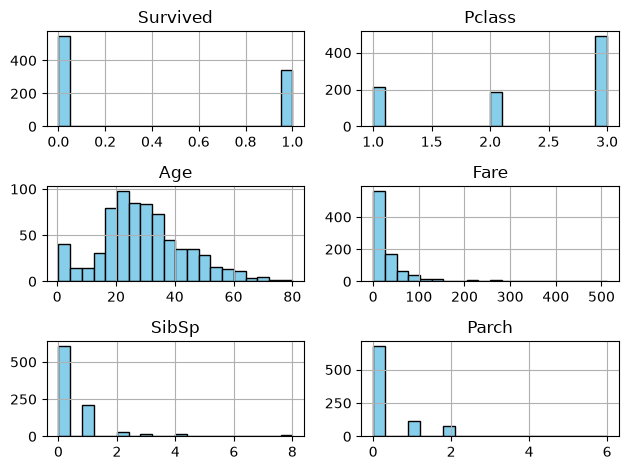

In [29]:
plt.figure(figsize=(15,10))
numerical_cols = [
    'Survived', 'Pclass', 'Age', 'Fare', 'SibSp', 'Parch'
]

train_df[numerical_cols].hist(
    bins=20,
    color='skyblue',
    edgecolor='black'
)
plt.tight_layout()
plt.show()

In [11]:
# Missing values
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [16]:
# Data Preprocessing
def data_preprocess(df):
    df = df.copy()

    df['Age'] = df['Age'].fillna(df['Age'].median())

    df['Fare'] = df['Fare'].fillna(df['Fare'].median())

    df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

    df['Sex'] = df['Sex'].map({'male' : 0, "female" : 1})

    df['Embarked'] = df['Embarked'].map({'S' : 0, 'C' : 1, 'Q' : 2}).fillna(0)

    return df

train_processed = data_preprocess(train_df)
test_processed = data_preprocess(test_df)

In [18]:
# Feature selection
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', "Embarked"]
X = train_processed[features]
y = train_processed['Survived']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Jumlah data training : {X_train.shape[0]} | Jumlah data validasi : {X_val.shape[0]}')

Jumlah data training : 712 | Jumlah data validasi : 179


In [20]:
# Membuat dan training model
model = LogisticRegression()
model.fit(X_train, y_train)

# evaluasi pada data validasi 
y_pred_val = model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_pred_val)

c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [22]:
# hasil evaluasi
print("HASIL EVALUASI MODEL")
print(f"Accuracy Score : {val_accuracy * 100:.2f}%")
print("\nClassification report")
print(classification_report(y_val, y_pred_val))

HASIL EVALUASI MODEL
Accuracy Score : 79.89%

Classification report
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       105
           1       0.77      0.73      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [ ]:
# memprediksi data
X_test = test_processed[features]

test_predictions = model.predict(X_test)

result = pd.DataFrame(
    {'PassengerId': test_df['PassengerId'], 'Survived' : test_predictions}
)

In [27]:
# membuat file csv dari hasil prediksi
result.to_csv("hasil_pred_titanic.csv", index=False)

print('File "hasil_pred_titanic.csv" sudah selesai dibuat.')
print("\n10 data pertama prediksi")
print(result.head(10))

File "hasil_pred_titanic.csv" sudah selesai dibuat.

10 data pertama prediksi
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
5          897         0
6          898         1
7          899         0
8          900         1
9          901         0
